1. Salario
2. Anos_Educ_Superior
3. Tempo_Empresa

In [ ]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

import statsmodels.api as sm

In [ ]:
df = pd.read_csv ('/content/drive/MyDrive/!dados/Analíse-Preditiva/base_funcionarios_v2.csv', sep=';', index_col='id')
df.head()

,Salario,Anos_Educ_Superior,Tempo_Empresa
id,,,
1,5517.4,3,3
2,6399.9,4,6
3,6206.7,6,3
4,6060.6,4,5
5,6122.7,2,9


In [ ]:
df.isna().sum

<bound method DataFrame.sum of     Salario  Anos_Educ_Superior  Tempo_Empresa
id                                            
1     False               False          False
2     False               False          False
3     False               False          False
4     False               False          False
5     False               False          False
6     False               False          False
7     False               False          False
8     False               False          False
9     False               False          False
10    False               False          False
11    False               False          False
12    False               False          False
13    False               False          False
14    False               False          False
15    False               False          False
16    False               False          False
17    False               False          False
18    False               False          False
19    False               False          False
20    False               False          False
21    False               False          False
22    False               False          False
23    False               False          False
24    False               False          False
25    False               False          False
26    False               False          False
27    False               False          False
28    False               False          False
29    False               False          False
30    False               False          False
31    False               False          False
32    False               False          False
33    False               False          False
34    False               False          False
35    False               False          False
36    False               False          False
37    False               False          False
38    False               False          False
39    False               False          False
40    False               False          False
41    False               False          False
42    False               False          False
43    False               False          False
44    False               False          False
45    False               False          False
46    False               False          False>

In [ ]:
df.describe().round(2)

,Salario,Anos_Educ_Superior,Tempo_Empresa
count,46.00,46.00,46.00
mean,6969.80,5.07,10.33
std,1924.87,2.84,7.60
min,4139.50,0.00,0.00
25%,5818.35,4.00,5.25
50%,6394.75,5.00,8.50
75%,7972.40,6.00,17.25
max,12118.10,12.00,27.00


In [ ]:
df.corr()

,Salario,Anos_Educ_Superior,Tempo_Empresa
Salario,1.000000,0.776992,0.765173
Anos_Educ_Superior,0.776992,1.000000,0.607486
Tempo_Empresa,0.765173,0.607486,1.000000


<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

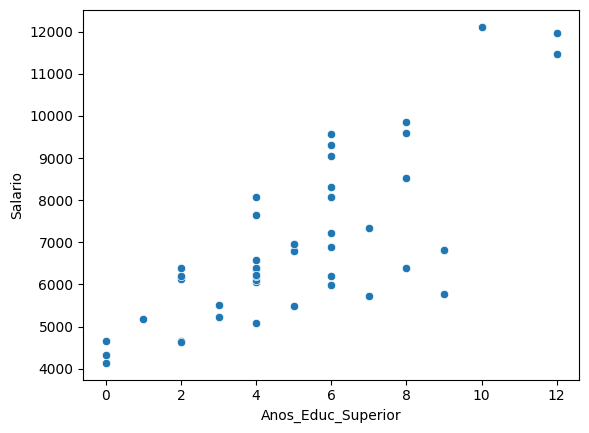

In [ ]:
sns.scatterplot(df, x='Anos_Educ_Superior', y='Salario')

<Axes: xlabel='Tempo_Empresa', ylabel='Salario'>

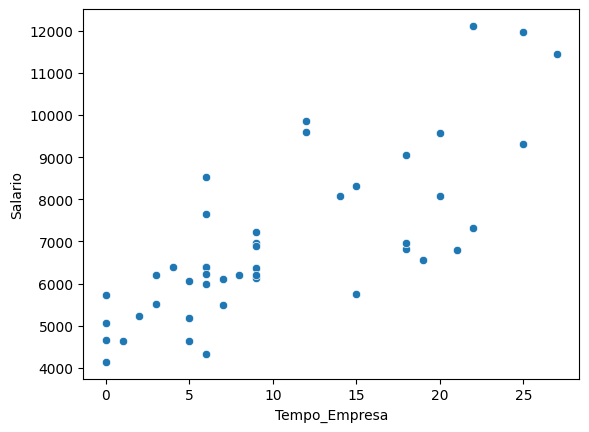

In [ ]:
sns.scatterplot(df, x='Tempo_Empresa', y='Salario')

<Axes: >

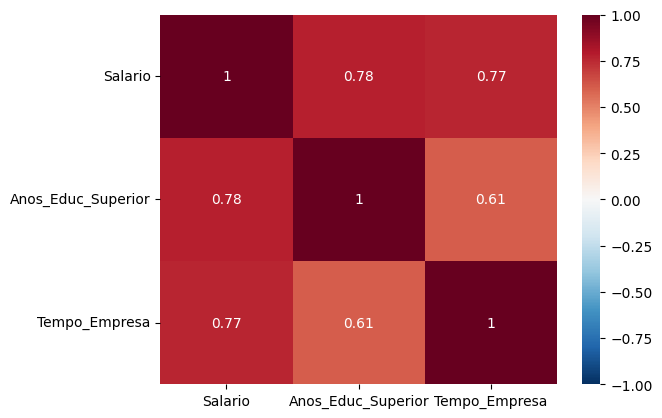

In [ ]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    cmap= 'RdBu_r',
    annot=True
)

In [ ]:
#variavel alvo / target
y = df['Salario']

#variaveis independentes / explicativas
df['intercepto'] = 1
x = df[['Anos_Educ_Superior','intercepto','Tempo_Empresa']]

In [ ]:
#Ajuste do modelo
# minimos quadrados ordinarios
modelo = sm.OLS(y,x)

In [ ]:
#treinamento
resultado = modelo.fit()

In [ ]:
print(resultado.summary())
#Porcentagem = 75%
#Anos_Educ_Superior = 334.39 - 526.73
#intercepto = 4301.80 - 4056.1
#Tempo_Empresa = 117.66

                            OLS Regression Results                            
Dep. Variable:                Salario   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.728
Method:                 Least Squares   F-statistic:                     61.17
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           2.66e-13
Time:                        17:18:26   Log-Likelihood:                -381.67
No. Observations:                  46   AIC:                             769.3
Df Residuals:                      43   BIC:                             774.8
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Anos_Educ_Superior   335.3868     66

In [ ]:
df['Novo Salario'] = df['Anos_Educ_Superior'] * 526.73 + 4301.80 + df['Tempo_Empresa'] * 117.66
display(df[['Salario','Novo Salario']])

,Salario,Novo Salario
id,,
1,5517.4,6234.97
2,6399.9,7114.68
3,6206.7,7815.16
4,6060.6,6997.02
5,6122.7,6414.20
6,6955.0,7994.39
7,7643.0,7114.68
8,6210.2,6296.54
9,5761.0,10807.27
